# Supplementary Figures S1, S3, S4 and S5

Supplementary Fig. S1: examples of national citation preference dynamics (the four panels are saved as separate files). Supplementary Fig. S3: edge weight distribution of the positive and negative edges. Supplementary Fig. S4: distribution of the citation preference strength relative to the null expectation. Supplementary Fig. S5: edge weight distribution of the inter- and intra-community edges.

It reads its input from the data folder (`path2data`). The figures are saved in the `figures` folder.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
from collections import defaultdict
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)

## Supplementary Fig. S1: examples of national citation preference dynamics

Panels A: US and CN, B: US and DE, C: SA and PK, D: IN and SG. The four panels are saved as separate files, and together, with the country names, as `FigSI_globalpolitics.pdf`.

In [2]:
# the colours of Supplementary Fig. S1
blue_colors = ['#03045E', '#023e8a', '#0077b6', '#0096c7', '#00b4d8', '#48cae4']
highlight_colors = ['#ef798a', '#f7B801', '#db3069']

# the significance of the citation preferences in Supplementary Fig. S1 uses the
# Holm-Sidak correction with alpha = 0.001
country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df = country_auc_df[country_auc_df['N']>=50]

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])
# one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
# when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

#country_auc_df = country_auc_df[country_auc_df['pvalue'] <= 0.05/50**2]

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.001, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

#focus_country = np.sort(countryprod.sort_values("NumberPublications", ascending=False).iloc[:100]['Country'].values)
#country_auc_df = country_auc_df[country_auc_df['CitedCountry'].isin(focus_country)]
#country_auc_df = country_auc_df[country_auc_df['CitingCountry'].isin(focus_country)]

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].reset_index(drop=True)
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].reset_index(drop=True)
#self_auc['CitedYear'] +=5
#net_auc['CitedYear'] +=5

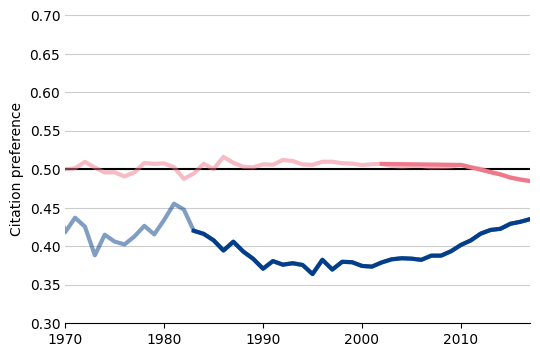

In [3]:
ex1 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'US', country_auc_df['CitedCountry'] == 'CN')]
ex2 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'CN', country_auc_df['CitedCountry'] == 'US')]

fig, ax = plt.subplots(1,1,figsize=(6,4))

ax.axhline(y=0.5, color='k')

ax.plot(ex1['CitedYear'].values, ex1['AUC'].values, color=blue_colors[1], alpha = 0.5, lw=3)
ax.plot(ex2['CitedYear'].values, ex2['AUC'].values, color=highlight_colors[0], alpha = 0.5, lw=3)

ax.plot(ex1[ex1['Significant']]['CitedYear'].values, ex1[ex1['Significant']]['AUC'].values, color=blue_colors[1], lw=3)
ax.plot(ex2[ex2['Significant']]['CitedYear'].values, ex2[ex2['Significant']]['AUC'].values, color=highlight_colors[0], lw=3)
    
ax.set_xlim([1970, 2017]) 
ax.set_ylim([0.3, 0.7])

#ax.set_yticks([0.5, 0.55, 0.6, 0.65])
ax.set_xticks([1970,1980,1990,2000,2010])

ax.grid(axis='y', which='major', color='0.8', linestyle='-')
ax.tick_params(axis='y', size=0)
ax.set_ylabel("Citation preference")

for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)

#plt.legend()

plt.savefig(os.path.join(path2figures, 'FigSI_globalpolitics_US_China_auc.pdf'), bbox_inches='tight')

plt.show()

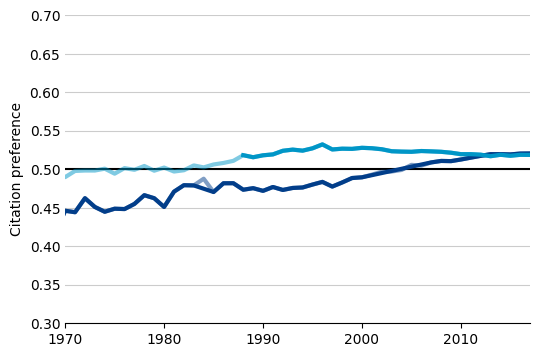

In [4]:
ex1 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'US', country_auc_df['CitedCountry'] == 'DE')]
ex2 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'DE', country_auc_df['CitedCountry'] == 'US')]

fig, ax = plt.subplots(1,1,figsize=(6,4))

ax.axhline(y=0.5, color='k')

ax.plot(ex1['CitedYear'].values, ex1['AUC'].values, color=blue_colors[1], alpha = 0.5, lw=3)
ax.plot(ex2['CitedYear'].values, ex2['AUC'].values, color=blue_colors[3], alpha = 0.5, lw=3)

idx = 11
ax.plot(ex1[ex1['Significant']]['CitedYear'].values[idx:], ex1[ex1['Significant']]['AUC'].values[idx:], color=blue_colors[1], lw=3)
ax.plot(ex2[ex2['Significant']]['CitedYear'].values[idx:], ex2[ex2['Significant']]['AUC'].values[idx:], color=blue_colors[3], lw=3)
    
ax.set_xlim([1970, 2017]) 
ax.set_ylim([0.3, 0.7])

#ax.set_yticks([0.5, 0.55, 0.6, 0.65])
ax.set_xticks([1970,1980,1990,2000,2010])

ax.grid(axis='y', which='major', color='0.8', linestyle='-')
ax.tick_params(axis='y', size=0)
ax.set_ylabel("Citation preference")

for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)

#plt.legend()

plt.savefig(os.path.join(path2figures, 'FigSI_globalpolitics_US_DE_auc.pdf'), bbox_inches='tight')

plt.show()

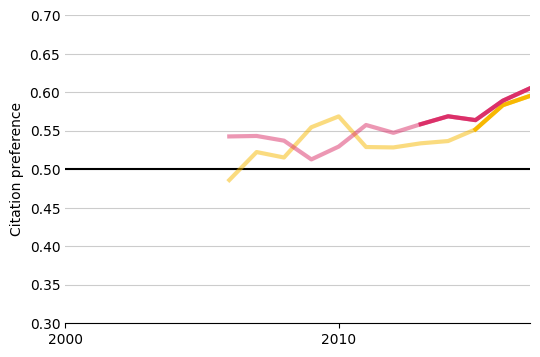

In [5]:
ex1 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'SA', country_auc_df['CitedCountry'] == 'PK')]
ex2 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'PK', country_auc_df['CitedCountry'] == 'SA')]

fig, ax = plt.subplots(1,1,figsize=(6,4))

ax.axhline(y=0.5, color='k')

ax.plot(ex1['CitedYear'].values, ex1['AUC'].values, color=highlight_colors[1], alpha = 0.5, lw=3)
ax.plot(ex2['CitedYear'].values, ex2['AUC'].values, color=highlight_colors[2], alpha = 0.5, lw=3)

idx = 1
ax.plot(ex1[ex1['Significant']]['CitedYear'].values[idx:], ex1[ex1['Significant']]['AUC'].values[idx:], color=highlight_colors[1], lw=3)
ax.plot(ex2[ex2['Significant']]['CitedYear'].values[idx:], ex2[ex2['Significant']]['AUC'].values[idx:], color=highlight_colors[2], lw=3)
    
ax.set_xlim([2000, 2017]) 
ax.set_ylim([0.3, 0.7])

#ax.set_yticks([0.5, 0.55, 0.6, 0.65])
ax.set_xticks([2000,2010])

ax.grid(axis='y', which='major', color='0.8', linestyle='-')
ax.tick_params(axis='y', size=0)
ax.set_ylabel("Citation preference")

for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)

#plt.legend()

plt.savefig(os.path.join(path2figures, 'FigSI_globalpolitics_SA_PK_auc.pdf'), bbox_inches='tight')

plt.show()

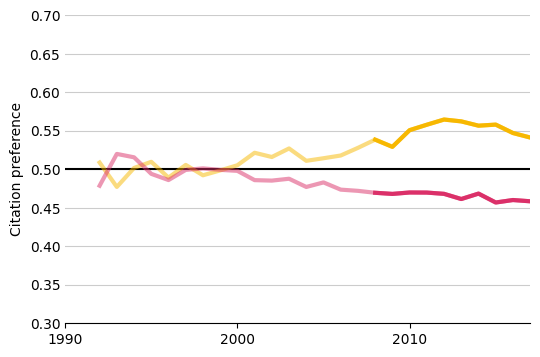

In [6]:
ex1 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'IN', country_auc_df['CitedCountry'] == 'SG')]
ex2 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == 'SG', country_auc_df['CitedCountry'] == 'IN')]

fig, ax = plt.subplots(1,1,figsize=(6,4))

ax.axhline(y=0.5, color='k')

ax.plot(ex1['CitedYear'].values, ex1['AUC'].values, color=highlight_colors[1], alpha = 0.5, lw=3)
ax.plot(ex2['CitedYear'].values, ex2['AUC'].values, color=highlight_colors[2], alpha = 0.5, lw=3)

idx = 0
ax.plot(ex1[ex1['Significant']]['CitedYear'].values[idx:], ex1[ex1['Significant']]['AUC'].values[idx:], color=highlight_colors[1], lw=3)
ax.plot(ex2[ex2['Significant']]['CitedYear'].values[idx:], ex2[ex2['Significant']]['AUC'].values[idx:], color=highlight_colors[2], lw=3)
    
ax.set_xlim([1990, 2017]) 
ax.set_ylim([0.3, 0.7])

#ax.set_yticks([0.5, 0.55, 0.6, 0.65])
ax.set_xticks([1990,2000,2010])

ax.grid(axis='y', which='major', color='0.8', linestyle='-')
ax.tick_params(axis='y', size=0)
ax.set_ylabel("Citation preference")

for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)

#plt.legend()

plt.savefig(os.path.join(path2figures, 'FigSI_globalpolitics_SG_IN_auc.pdf'), bbox_inches='tight')

plt.show()

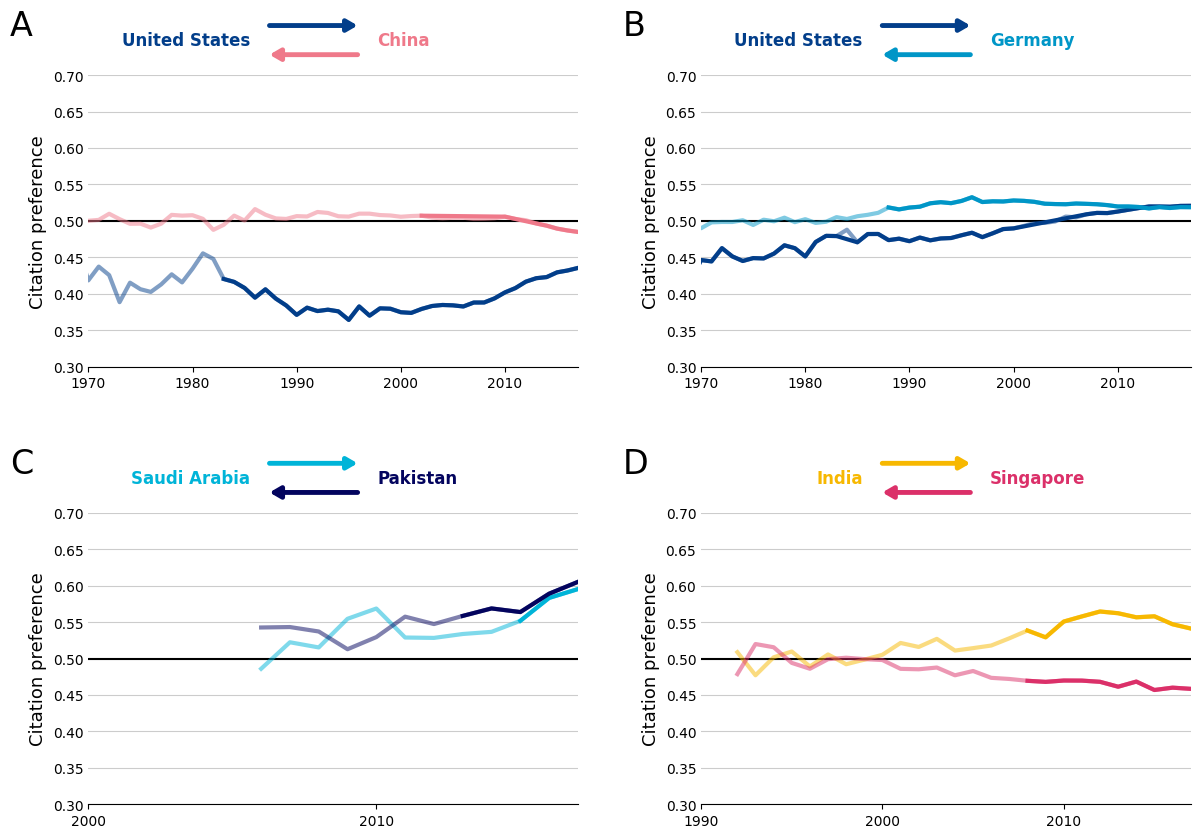

In [7]:
# Supplementary Fig. S1: the four panels in one figure, with the country names in place of the country maps.
# Each panel shows the citation preference of each country of a pair toward the other one; the arrow from
# country X to country Y marks the citation preference of X (citing) toward Y (cited). Faded lines: all years;
# solid lines: the statistically significant years (as in the single-panel figures above).
country_names = {'US':'United States', 'CN':'China', 'DE':'Germany', 'SA':'Saudi Arabia', 'PK':'Pakistan',
                 'IN':'India', 'SG':'Singapore'}

# panel, first country, second country, colour of first -> second, colour of second -> first,
# first significant year plotted (idx, as above), x-axis limits and ticks
s1_panels = [('A', 'US', 'CN', blue_colors[1], highlight_colors[0], 0, [1970, 2017], [1970, 1980, 1990, 2000, 2010]),
             ('B', 'US', 'DE', blue_colors[1], blue_colors[3], 11, [1970, 2017], [1970, 1980, 1990, 2000, 2010]),
             ('C', 'SA', 'PK', blue_colors[4], blue_colors[0], 1, [2000, 2017], [2000, 2010]),
             ('D', 'IN', 'SG', highlight_colors[1], highlight_colors[2], 0, [1990, 2017], [1990, 2000, 2010])]

def country_label(ax, c1, c2, color12, color21):
    """Country names, in the colour of their line (as the citing country), with the arrows c1 -> c2 (top) and
    c2 -> c1 (bottom) above the panel."""
    ytop, ybottom = 1.17, 1.07
    ax.text(0.33, (ytop + ybottom)/2, country_names[c1], transform=ax.transAxes, ha='right', va='center', fontsize=12,
            color=color12, fontweight='bold')
    ax.text(0.59, (ytop + ybottom)/2, country_names[c2], transform=ax.transAxes, ha='left', va='center', fontsize=12,
            color=color21, fontweight='bold')
    arrow = dict(arrowstyle='-|>,head_length=0.6,head_width=0.35', lw=3.5, shrinkA=0, shrinkB=0)
    ax.annotate('', xy=(0.55, ytop), xytext=(0.37, ytop), xycoords='axes fraction', arrowprops=dict(color=color12, **arrow))
    ax.annotate('', xy=(0.37, ybottom), xytext=(0.55, ybottom), xycoords='axes fraction', arrowprops=dict(color=color21, **arrow))

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
for ax, (panel, c1, c2, color12, color21, idx, xlim, xticks) in zip(axes.flatten(), s1_panels):
    ex1 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == c1, country_auc_df['CitedCountry'] == c2)]
    ex2 = country_auc_df[np.logical_and(country_auc_df['CitingCountry'] == c2, country_auc_df['CitedCountry'] == c1)]

    ax.axhline(y=0.5, color='k')
    ax.plot(ex1['CitedYear'].values, ex1['AUC'].values, color=color12, alpha=0.5, lw=3)
    ax.plot(ex2['CitedYear'].values, ex2['AUC'].values, color=color21, alpha=0.5, lw=3)
    ax.plot(ex1[ex1['Significant']]['CitedYear'].values[idx:], ex1[ex1['Significant']]['AUC'].values[idx:], color=color12, lw=3)
    ax.plot(ex2[ex2['Significant']]['CitedYear'].values[idx:], ex2[ex2['Significant']]['AUC'].values[idx:], color=color21, lw=3)

    ax.set_xlim(xlim)
    ax.set_ylim([0.3, 0.7])
    ax.set_xticks(xticks)
    ax.grid(axis='y', which='major', color='0.8', linestyle='-')
    ax.tick_params(axis='y', size=0)
    ax.set_ylabel("Citation preference", fontsize=13)
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)

    country_label(ax, c1, c2, color12, color21)
    ax.text(-0.16, 1.17, panel, transform=ax.transAxes, fontsize=24, va='center', ha='left')

plt.tight_layout(h_pad=4, w_pad=4)
plt.savefig(os.path.join(path2figures, 'FigSI_globalpolitics.pdf'), bbox_inches='tight')
plt.show()

In [8]:
# the values plotted in Supplementary Fig. S1 (both directions of the four country pairs), kept for the Source Data
s1_pairs = [('A', 'US', 'CN'), ('B', 'US', 'DE'), ('C', 'SA', 'PK'), ('D', 'IN', 'SG')]
figS1_data = []
for panel, c1, c2 in s1_pairs:
    for citing, cited in [(c1, c2), (c2, c1)]:
        ex = country_auc_df[(country_auc_df['CitingCountry'] == citing) & (country_auc_df['CitedCountry'] == cited)]
        figS1_data.append(ex[['CitingCountry', 'CitedCountry', 'CitedYear', 'AUC', 'Cov', 'N', 'Zscore', 'Significant']].assign(Panel=panel))
figS1_data = pd.concat(figS1_data, ignore_index=True)

## The cumulative citation preference network (1990-2017)

In [9]:

country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])

    
country_auc_df = country_auc_df[country_auc_df['N']>=50].reset_index(drop=True)


# one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
# when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
net_auc = net_auc[net_auc['Significant']]
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
self_auc = self_auc[self_auc['Significant']]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

connected_countries = np.sort(np.unique(net_auc[net_auc['Zscore'] > 0][['CitingCountry', 'CitedCountry']].values.flatten()))
print(connected_countries.shape)

syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
cumulative_net = net_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')

(93,)


## Supplementary Fig. S3: edge weight distribution

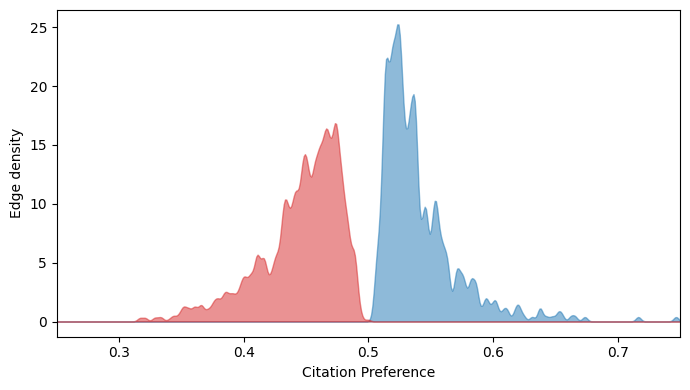

In [10]:
from sklearn.neighbors import KernelDensity

def make_kde(x, x_d=np.linspace(0, 1, 1000), bandwidth=0.01, color='k', alpha=0.5, ax=None):
    kde = KernelDensity(bandwidth=bandwidth, kernel='gaussian')
    kde.fit(x[:, None])

    # score_samples returns the log of the probability density
    logprob = kde.score_samples(x_d[:, None])

    ax.fill_between(x_d, np.exp(logprob), alpha=alpha, color=color)
    return ax

eurofund_palette = ['#0D95D0', '#7DC462', '#E72F52', '#774FA0', '#EFB743', '#D44627']

fig, ax = plt.subplots(1,1,figsize=(7,4))

make_kde(cumulative_net[cumulative_net['Zscore'] > 0]['AUC'].values, x_d=np.linspace(0, 1, 1000), bandwidth=0.002, color=sns.color_palette()[0], 
                 alpha=0.5, ax=ax)

make_kde(cumulative_net[cumulative_net['Zscore'] < 0]['AUC'].values, x_d=np.linspace(0, 1, 1000), bandwidth=0.002, color=sns.color_palette()[3], 
                 alpha=0.5, ax=ax)


ax.set_xlim([0.25, 0.75])
ax.set_xlabel('Citation Preference')
ax.set_ylabel('Edge density')
plt.tight_layout()    
#ax.set_xlabel('Node balance', fontsize=20)
plt.savefig(os.path.join(path2figures, 'FigSI_AUCdist.pdf'))
plt.show()

## Supplementary Fig. S4: citation preference strength relative to the null expectation

[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13
 0.14 0.15 0.16 0.17 0.18 0.19 0.2  0.21 0.22 0.23 0.24 0.25]
[  35  264  614  941 1175 1404 1572 1667 1763 1829 1878 1916 1941 1964
 1983 1993 1998 2003 2005 2005 2005 2006 2006 2006 2007]
[0.01743896 0.13153961 0.30592925 0.46885899 0.58545092 0.69955157
 0.78325859 0.83059292 0.87842551 0.91131041 0.93572496 0.95465869
 0.9671151  0.97857499 0.98804185 0.99302441 0.9955157  0.99800698
 0.99900349 0.99900349 0.99900349 0.99950174 0.99950174 0.99950174
 1.        ] 2007


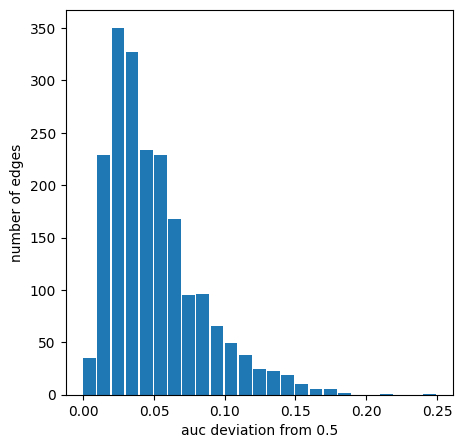

In [11]:
aucdist, aucbin = np.histogram(np.abs(cumulative_net['AUC'].values - 0.5), bins=np.linspace(0,0.25,26))
print(aucbin)
print(np.cumsum(aucdist))
print(np.cumsum(aucdist)/np.sum(aucdist), np.sum(aucdist))
fig, ax = plt.subplots(1,1,figsize=(5,5))

ax.bar(aucbin[:-1]+0.009/2, aucdist, width=0.009)
ax.set_ylabel('number of edges')
ax.set_xlabel('auc deviation from 0.5')
plt.savefig(os.path.join(path2figures, 'SI_aucdeviation.pdf'))
plt.show()

## Supplementary Fig. S5: edge weight distribution of inter- and intra-community edges

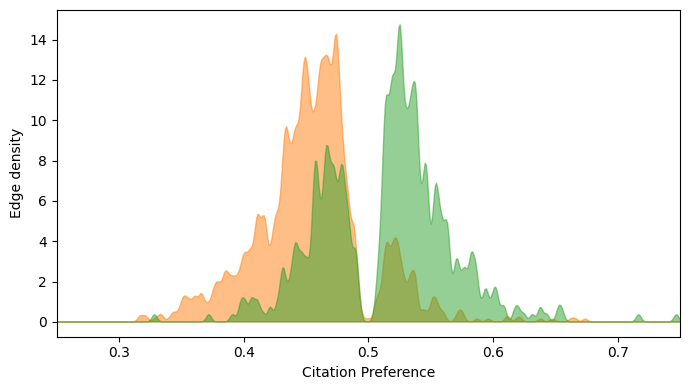

In [12]:
cumulative_net['SourceCommunity'] = cumulative_net['CitingCountry'].map(country2comm)
cumulative_net['TargetCommunity'] = cumulative_net['CitedCountry'].map(country2comm)
cumulative_net['InterCommunity'] = cumulative_net['SourceCommunity'] != cumulative_net['TargetCommunity']


fig, ax = plt.subplots(1,1,figsize=(7,4))

make_kde(cumulative_net[cumulative_net['InterCommunity'] ]['AUC'].values, x_d=np.linspace(0, 1, 1000), bandwidth=0.002, color=sns.color_palette()[1], 
                 alpha=0.5, ax=ax)

make_kde(cumulative_net[~cumulative_net['InterCommunity'] ]['AUC'].values, x_d=np.linspace(0, 1, 1000), bandwidth=0.002, color=sns.color_palette()[2], 
                 alpha=0.5, ax=ax)


ax.set_xlim([0.25, 0.75])
ax.set_xlabel('Citation Preference')
ax.set_ylabel('Edge density')
plt.tight_layout()    
#ax.set_xlabel('Node balance', fontsize=20)
plt.savefig(os.path.join(path2figures, 'FigSI_InterCommunityEdgeWeights.pdf'))
plt.show()

## Source Data for Supplementary Figs. S1, S3, S4 and S5

The values plotted in each figure, written to `Source Data/SourceData_FigS1.xlsx`, `SourceData_FigS3.xlsx`, `SourceData_FigS4.xlsx` and `SourceData_FigS5.xlsx`.

In [13]:
from sourcedatautils import write_source_data, country2commlabel

edge_names = {'CitingCountry':'Citing country', 'CitedCountry':'Cited country', 'CitedYear':'Year of the most recent significant preference', 'AUC':'AUC', 'Zscore':'Z-score'}

# Supplementary Fig. S1
s1 = figS1_data.rename(columns={'CitingCountry':'Citing country', 'CitedCountry':'Cited country', 'CitedYear':'Year',
                                 'Cov':'Variance', 'Zscore':'Z-score',
                                 'Significant':'Significant (Holm-Sidak, alpha = 0.001)'})
s1 = s1[['Panel', 'Citing country', 'Cited country', 'Year', 'AUC', 'Variance', 'N', 'Z-score', 'Significant (Holm-Sidak, alpha = 0.001)']]
write_source_data('SourceData_FigS1.xlsx', 'Supplementary Figure 1: Examples of national citation preference dynamics.',
                  ('National citation preference (AUC) over time for both directions of four country pairs: A) US and CN, '
                   'B) US and DE, C) SA and PK, D) IN and SG (N >= 50). Solid lines in the figure mark the statistically '
                   'significant years.'),
                  [('S1', 'Citation preference of each citing country toward the cited country in each year.', s1)])

# the edges of the cumulative network (Supplementary Figs. S3-S5)
edges = cumulative_net[['CitingCountry', 'CitedCountry', 'CitedYear', 'AUC', 'Zscore']].rename(columns=edge_names)
edges['Sign'] = np.where(cumulative_net['Zscore'] > 0, 'Positive', 'Negative')

write_source_data('SourceData_FigS3.xlsx', 'Supplementary Figure 3: International citation preference network edge weight distribution.',
                  ('Citation preference (AUC) of the statistically significant positive and negative edges in the cumulative '
                   'network (1990-2017); the figure shows their kernel density (bandwidth 0.002).'),
                  [('S3', 'Edges of the cumulative network.', edges)])

s4_edges = edges.copy()
s4_edges['|AUC - 0.5|'] = np.abs(cumulative_net['AUC'].values - 0.5)
s4_bins = pd.DataFrame({'Bin lower': aucbin[:-1], 'Bin upper': aucbin[1:], 'Number of edges': aucdist})
write_source_data('SourceData_FigS4.xlsx', 'Supplementary Figure 4: Distribution of citation preference strengths relative to null expectation.',
                  'Absolute deviation |AUC - 0.5| of each edge of the cumulative network, and the histogram plotted.',
                  [('S4 histogram', 'Number of edges in each bin of |AUC - 0.5|.', s4_bins),
                   ('S4 edges', 'Edges of the cumulative network with |AUC - 0.5|.', s4_edges)])

s5_edges = edges.copy()
s5_edges['Citing community'] = cumulative_net['CitingCountry'].map(country2commlabel).values
s5_edges['Cited community'] = cumulative_net['CitedCountry'].map(country2commlabel).values
s5_edges['Inter-community'] = cumulative_net['InterCommunity'].values
write_source_data('SourceData_FigS5.xlsx', 'Supplementary Figure 5: Edge weight distribution of inter- and intra-community edges.',
                  ('Citation preference (AUC) of the edges of the cumulative network, with the communities (1-5, as in Fig. 2) '
                   'of the citing and cited countries; edges with a country outside the five communities count as '
                   'inter-community. The figure shows the kernel density (bandwidth 0.002) of inter- and intra-community edges.'),
                  [('S5', 'Edges of the cumulative network.', s5_edges)])

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS1.xlsx


wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS3.xlsx


wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS4.xlsx


wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS5.xlsx


wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
